![SPAIN 2035 - ¿Podré quedarme en Málaga?](web/portada_SPAIN2035.png)

# SPAIN 2035 · ¿Podré quedarme en Málaga?
**Proyecto 7 · Regresión y análisis exploratorio**

Una persona empieza a trabajar como analista de datos en Málaga. Le gustaría quedarse, vivir sola y ahorrar 200 € al mes. ¿Qué alquiler puede pagar? ¿Cuánto cambia su margen si gana experiencia? El contexto es un país cuyo PIB por habitante ha crecido y cuya evaluación media de vida ha seguido otra trayectoria.

**Recorrido de la exposición**
1. Comparar el PIB por persona y la satisfacción con la vida en España y seis países europeos.
2. Estimar el alquiler de una sección censal a un año y medir el error en euros.
3. Convertir las predicciones y los alquileres observados en preguntas de presupuesto, ahorro y acceso a la compra.

**Cómo reproducirlo.** Abre este notebook en VS Code con el ZIP Atlas_Malaga_datos.zip en la misma carpeta. Selecciona un kernel de Python con NumPy, pandas, Matplotlib y scikit-learn y pulsa **Ejecutar todo**. Los escenarios de gasto, ahorro y financiación se pueden modificar en sus celdas.

In [25]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

archivo = Path("Atlas_Malaga_datos.zip")
if not archivo.exists():
    archivo = Path("upload") / archivo
def leer(nombre, **opciones):
    with ZipFile(archivo) as atlas, atlas.open("Datos_Malaga/" + nombre + ".csv") as fichero:
        return pd.read_csv(fichero, **opciones)

objetivo = "alquiler_mediano_eur_mes"
panel = leer("alquiler_seccion_malaga", dtype={"zona": str})
ciudad = leer("alquiler_municipio_malaga").sort_values("anio")
# Cada fila debe identificar una única sección y un único año. Un duplicado duplicaría su peso al evaluar.
assert not panel.duplicated(["zona", "anio"]).any()
print(f"{panel.zona.nunique()} secciones · {len(panel)} registros · {panel[objetivo].count()} medianas publicadas")
print(ciudad[["anio", objetivo]].tail(4).round(2).to_string(index=False))

436 secciones · 6104 registros · 5182 medianas publicadas
 anio  alquiler_mediano_eur_mes
 2021                    600.00
 2022                    625.00
 2023                    665.85
 2024                    718.33


## ¿Cómo evolucionan España y los países de comparación?
Comparamos los primeros y últimos años comunes con datos completos de PIB real por persona (PPA, dólares internacionales de 2021) y evaluación de vida (escala 0–10, media trienal del WHR). El porcentaje mide el cambio acumulado del PIB por persona. La variación de bienestar se expresa en puntos. Estos promedios nacionales dan contexto a la decisión personal.

In [ ]:
economia = leer("economia_siete_paises")
whr = leer("bienestar_whr_siete_paises")
paises = {"ESP":"Spain", "DEU":"Germany", "NLD":"Netherlands", "DNK":"Denmark",
          "CHE":"Switzerland", "NOR":"Norway", "SWE":"Sweden"}
pib = economia[economia.codigo == "NY.GDP.PCAP.PP.KD"].copy()
pib["Country name"] = pib.iso3.map(paises)
vida = "Life evaluation (3-year average)"
comparacion = pib.merge(whr, left_on=["Country name", "anio"], right_on=["Country name", "Year"]).dropna(subset=["valor", vida])
# Exigimos cobertura de los siete países al elegir los extremos del periodo para comparar la misma ventana.
cobertura_pais = comparacion.groupby("anio").iso3.nunique()
anios = cobertura_pais[cobertura_pais == len(paises)].index
inicio, fin = min(anios), max(anios)
antes = comparacion[comparacion.anio == inicio].set_index("iso3")
despues = comparacion[comparacion.anio == fin].set_index("iso3")
resumen = pd.DataFrame({"PIB por persona (%)": 100*(despues.valor/antes.valor-1),
                        "Cambio en bienestar (puntos)": despues[vida]-antes[vida]})
print(f"{inicio}–{fin}")
print(resumen.round(2).to_string())

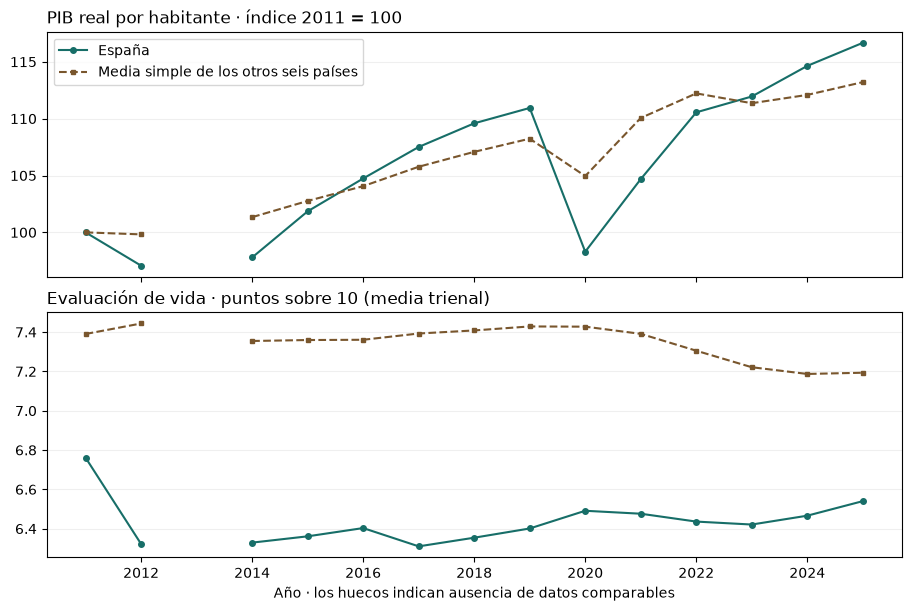

In [ ]:
fig, ejes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
for indicador, eje, titulo in zip(["valor", vida], ejes, ["PIB real por habitante · índice 2011 = 100", "Evaluación de vida · puntos sobre 10 (media trienal)"]):
    series = comparacion.pivot(index="anio", columns="iso3", values=indicador).reindex(range(inicio, fin + 1))
    if indicador == "valor":
        # Expresar 2011 como 100 permite comparar la evolución de países con niveles de renta distintos.
        series = 100 * series / series.loc[inicio]
    restantes = series.drop(columns="ESP")
    referencia = restantes.mean(axis=1).where(restantes.count(axis=1).eq(6))
    eje.plot(series.index, series.ESP, "o-", color="#176e68", label="España", markersize=4)
    eje.plot(series.index, referencia, "s--", color="#79562d", label="Media simple de los otros seis países", markersize=3)
    eje.set_title(titulo, loc="left")
    eje.grid(axis="y", alpha=.2)
ejes[0].legend()
ejes[1].set_xlabel("Año · los huecos indican ausencia de datos comparables")
plt.show()

## España 2035 · ¿qué ocurriría si continuara el crecimiento histórico?
Partimos del PIB real por habitante de España en 2025 (Banco Mundial, PPA a precios constantes de 2021). Calculamos el ritmo anual compuesto de dos periodos históricos: 2011–2025 y 2015–2025. En cada escenario mantenemos ese ritmo hasta 2035. Añadimos una referencia con crecimiento cero. Un índice de 110 equivale a un PIB por habitante un 10 % superior al de 2025.

La fórmula es $I_t=100(1+g)^{t-2025}$, donde $g$ es el crecimiento anual supuesto. Elegir otros periodos cambiaría el resultado. Los escenarios describen posibilidades y carecen de probabilidades asignadas.

PIB real por habitante · índice 2025 = 100
                 Ritmo anual (%)    2030    2035
Sin crecimiento             0.00  100.00  100.00
Ritmo 2011–2025             1.11  105.66  111.64
Ritmo 2015–2025             1.37  107.03  114.55


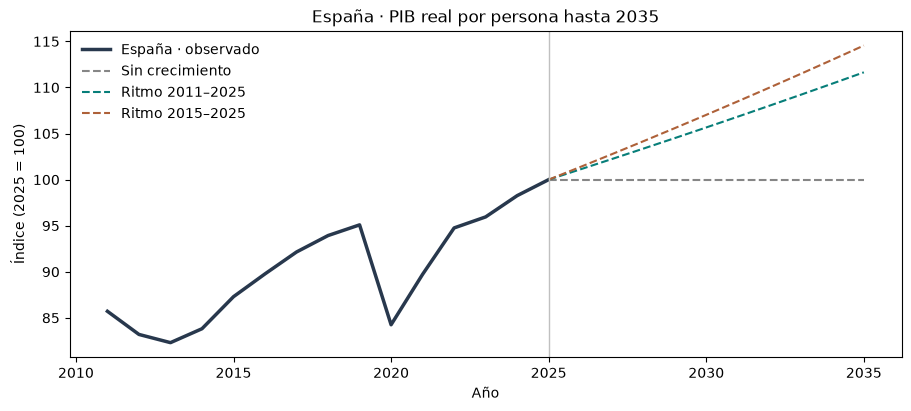

Evaluación de vida WHR: 6.761 en 2011 y 6.540 en 2025.
 oleada                              respuesta  porcentaje_esma
   2023      Muy satisfecho de vivir en Málaga             57.1
   2023 Bastante satisfecho de vivir en Málaga             35.4
   2023       Vivienda como problema principal             33.0


In [ ]:
serie_es = pib.loc[pib.iso3.eq("ESP")].set_index("anio").valor.sort_index().dropna()
base_escenario = 2025
tasas = {"Sin crecimiento": 0.0}
# Los dos años de arranque permiten comprobar cuánto cambia la proyección al elegir otro periodo histórico.
for desde in [2011, 2015]:
    tasas[f"Ritmo {desde}–2025"] = (serie_es.at[2025] / serie_es.at[desde]) ** (1 / (2025-desde)) - 1

proyecciones = pd.DataFrame(index=range(2025, 2036))
for nombre, tasa in tasas.items():
    proyecciones[nombre] = 100 * (1 + tasa) ** (proyecciones.index - base_escenario)
tabla_pib = proyecciones.loc[[2030, 2035]].T.copy()
tabla_pib.insert(0, "Ritmo anual (%)", pd.Series(tasas)*100)
print("PIB real por habitante · índice 2025 = 100")
print(tabla_pib.round(2).to_string())
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
observado = serie_es.loc[2011:2025] / serie_es.at[2025] * 100
ax.plot(observado, color="#28384d", linewidth=2.5, label="España · observado")
for nombre, color in zip(tasas, ["#868686", "#077e79", "#ae6139"]):
    ax.plot(proyecciones[nombre], "--", color=color, label=nombre)
ax.axvline(2025, color="silver", linewidth=1)
ax.set(title="España · PIB real por persona hasta 2035", ylabel="Índice (2025 = 100)", xlabel="Año")
ax.legend(frameon=False)
plt.show()

vida_es = comparacion[comparacion.iso3.eq("ESP")].set_index("anio")[vida]
print(f"Evaluación de vida WHR: {vida_es.at[2011]:.3f} en 2011 y {vida_es.at[2025]:.3f} en 2025.")
esma = leer("bienestar_esma")
print(esma.to_string(index=False))

### ¿Qué podemos decir de la felicidad?
Entre los extremos del periodo 2011–2025, el PIB por persona en España creció mientras la evaluación media de vida del WHR descendió. Son dos observaciones nacionales agregadas. Proyectar el PIB hasta 2035 por sí solo no permite asignar una puntuación de felicidad futura ni estimar la satisfacción individual de quien decide quedarse.

La encuesta ESMA de 2023 aporta una mirada local: el 57,1 % declaró estar muy satisfecho de vivir en Málaga y el 35,4 %, bastante satisfecho. Juntas, esas respuestas suman un 92,5 %. La pregunta local se refiere al lugar donde se vive; el WHR mide la evaluación general de la vida en una escala de 0 a 10. Para alguien que empieza como analista, estos datos contextualizan la decisión junto con un indicador personal que sí se puede calcular: el dinero que le queda después del alquiler y los demás gastos.

## ¿Qué observa el modelo?
SERPAVI recoge alquileres declarados. La serie municipal procede de la tabla del municipio. El recuento por sección permite ver cómo cambia la cobertura de los datos que usaremos para entrenar.

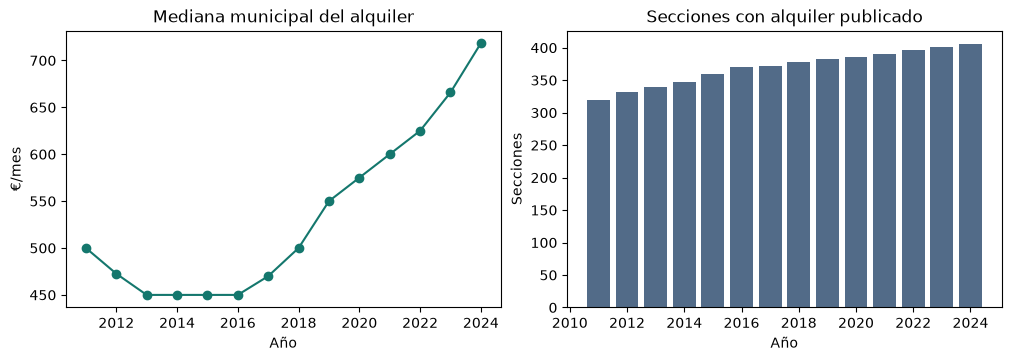

In [ ]:
# Contamos medianas publicadas. El número de filas también incluye las secciones sin importe.
cobertura = panel.groupby("anio")[objetivo].count()
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
ejes[0].plot(ciudad.anio, ciudad[objetivo], "o-", color="#14776d")
ejes[0].set(title="Mediana municipal del alquiler", xlabel="Año", ylabel="€/mes")
ejes[1].bar(cobertura.index, cobertura, color="#526b88")
ejes[1].set(title="Secciones con alquiler publicado", xlabel="Año", ylabel="Secciones")
plt.show()

## ¿Cuánto ayuda conocer un alquiler anterior?
Para cada horizonte emparejamos el alquiler de una sección con el publicado exactamente 1, 3, 6 u 11 años antes. Ajustamos una recta a cada horizonte. Para evaluar cada año, el entrenamiento termina en el año de origen de la predicción o antes de 2023, lo que ocurra primero. Así se reproduce qué datos se habrían conocido entonces. Comparamos con mantener el alquiler de origen. El MAE mide el error absoluto medio en euros al mes.

In [ ]:
def pares(horizonte):
    origen = panel[["zona", "anio", objetivo]].rename(columns={objetivo: "anterior"})
    # Ejemplo a un año: la mediana de 2022 se une a la fila de 2023 de la misma sección.
    origen["anio"] += horizonte
    return panel.merge(origen, on=["zona", "anio"]).dropna(subset=["anterior", objetivo])

def evaluar(horizonte):
    datos = pares(horizonte)
    resultados = []
    for anio in [2023, 2024]:
        # El último año permitido depende de cuánto se retrocede para emitir la predicción.
        corte = min(2022, anio - horizonte)
        entrenamiento = datos[datos.anio <= corte]
        prueba = datos[datos.anio == anio]
        if entrenamiento.empty or prueba.empty:
            continue
        modelo = LinearRegression().fit(entrenamiento[["anterior"]], entrenamiento[objetivo])
        for grupo, filas in [("entrenamiento", entrenamiento), ("validación", prueba)]:
            pred = modelo.predict(filas[["anterior"]])
            resultados.append([horizonte, anio, grupo, len(filas),
                               mean_absolute_error(filas[objetivo], pred),
                               mean_absolute_error(filas[objetivo], filas.anterior)])
    return resultados

columnas = ["horizonte", "año evaluado", "grupo", "n", "MAE modelo", "MAE referencia"]
metricas = pd.DataFrame([r for h in [1, 3, 6, 11] for r in evaluar(h)], columns=columnas)
print(metricas[metricas.grupo == "validación"].round(2).to_string(index=False))
anual = metricas[(metricas.horizonte == 1) & (metricas.grupo == "validación")]
mae_val = (anual["MAE modelo"] * anual.n).sum() / anual.n.sum()
mae_train = metricas.loc[(metricas.horizonte == 1) & (metricas.grupo == "entrenamiento"), "MAE modelo"].iloc[0]
print(f"Un año · MAE de entrenamiento {mae_train:.2f} · validación {mae_val:.2f} · brecha relativa {100*(mae_val/mae_train-1):.1f}%")

 horizonte  año evaluado      grupo   n  MAE modelo  MAE referencia
         1          2023 validación 396       30.36           42.90
         1          2024 validación 401       37.28           52.28
         3          2023 validación 385       66.84           98.96
         3          2024 validación 390       78.85          125.32
         6          2023 validación 371      204.25          193.02
         6          2024 validación 378      209.34          218.19
Un año · MAE de entrenamiento 27.36 · validación 33.84 · brecha relativa 23.7%


El corte de 2024 deja seis años hasta 2030 y once hasta 2035. La serie empieza en 2011. A once años faltan pares históricos para entrenar y evaluar respetando las fechas. La tabla muestra únicamente horizontes evaluables. Dos años de validación también limitan lo que puede concluirse sobre otros ciclos del mercado.

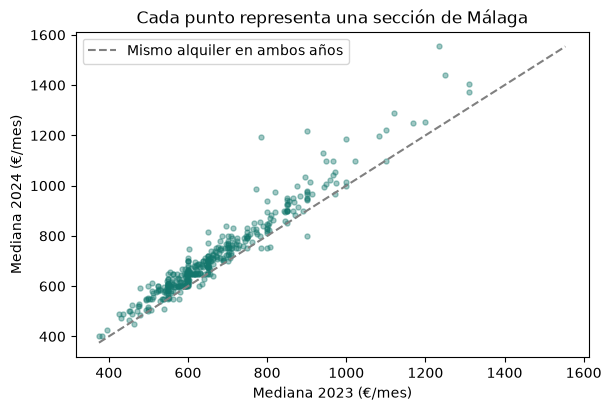

In [ ]:
datos = pares(1)
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
recientes = datos[datos.anio == 2024]
ax.scatter(recientes.anterior, recientes[objetivo], alpha=.4, s=13, color="#14776d")
limites = [recientes[["anterior", objetivo]].min().min(), recientes[["anterior", objetivo]].max().max()]
# En la diagonal, el alquiler es idéntico en ambos años. Los puntos por encima corresponden a subidas.
ax.plot(limites, limites, "--", color="gray", label="Mismo alquiler en ambos años")
ax.set(xlabel="Mediana 2023 (€/mes)", ylabel="Mediana 2024 (€/mes)", title="Cada punto representa una sección de Málaga")
ax.legend()
plt.show()

## Segunda prueba · ¿ayuda conocer la tendencia reciente?
Para predecir un año usamos tres datos que corresponden a años anteriores: el último alquiler de la sección, su cambio durante el año anterior y el cambio municipal durante ese mismo periodo. Suponemos que los datos del año de origen ya se han publicado. Comparamos todos los métodos en las mismas secciones con dos años consecutivos de historial. El objetivo es reducir el error en euros.

En cada corte de 2018 a 2022 entrenamos con los años anteriores y evaluamos el año siguiente al último de entrenamiento. Elegimos la regresión con menor MAE agregado en esos cinco cortes. Después congelamos sus coeficientes con entrenamiento hasta 2022 y medimos el rendimiento en 2023 y 2024 usando los alquileres anteriores disponibles para cada predicción. Estos dos años ya se habían inspeccionado en la primera prueba, por lo que son una comprobación retrospectiva.

In [ ]:
historial = pares(1)
dos_atras = panel[["zona", "anio", objetivo]].rename(columns={objetivo: "hace_dos"})
dos_atras["anio"] += 2
historial = historial.merge(dos_atras, on=["zona", "anio"])
# Para predecir 2024 restamos 2022 a 2023. Usar la variación de 2024 revelaría parte del resultado.
historial["cambio_seccion"] = historial.anterior - historial.hace_dos
municipal = ciudad.set_index("anio")[objetivo]
historial["cambio_ciudad"] = ((historial.anio - 1).map(municipal)
                             - (historial.anio - 2).map(municipal))
historial = historial.dropna(subset=["cambio_seccion", "cambio_ciudad"])
variables = {"Alquiler previo": ["anterior"],
             "Con tendencia local": ["anterior", "cambio_seccion"],
             "Con tendencia local y municipal": ["anterior", "cambio_seccion", "cambio_ciudad"]}
def medir(verdad, prediccion):
    return mean_absolute_error(verdad, prediccion)

cortes = []
# Todas las secciones de un año pasan juntas a validación para simular una predicción en el tiempo.
for anio in range(2018, 2023):
    train = historial[historial.anio < anio]
    val = historial[historial.anio == anio]
    for nombre, cols in variables.items():
        ajuste = LinearRegression().fit(train[cols], train[objetivo])
        cortes.append([anio, nombre, len(val), medir(val[objetivo], ajuste.predict(val[cols]))])

cv = pd.DataFrame(cortes, columns=["Año", "Modelo", "n", "MAE"])
print(cv.pivot(index="Año", columns="Modelo", values="MAE").round(2).to_string())
ranking = (cv.MAE * cv.n).groupby(cv.Modelo).sum() / cv.groupby("Modelo").n.sum()
print(ranking.sort_values().round(2).to_string())
ganador = ranking.idxmin()
cols = variables[ganador]

Modelo  Alquiler previo  Con tendencia local  Con tendencia local y municipal
Año                                                                          
2018              29.04                31.19                            21.34
2019              48.41                50.62                            27.57
2020              22.26                22.11                            48.57
2021              24.98                24.72                            24.07
2022              26.82                26.51                            23.87
Modelo
Con tendencia local y municipal    29.11
Alquiler previo                    30.23
Con tendencia local                30.94


                  n  Repetir alquiler  Alquiler previo  Con tendencia local  Con tendencia local y municipal
Periodo                                                                                                     
Entrenamiento  3549             28.50            26.33                26.29                            22.98
2023            390             43.09            28.64                28.66                            25.64
2024            396             52.17            34.62                34.99                            28.57
2023–2024       786             47.67            31.65                31.85                            27.12
Modelo elegido: Con tendencia local y municipal. Brecha relativa de MAE: 18.0 %.


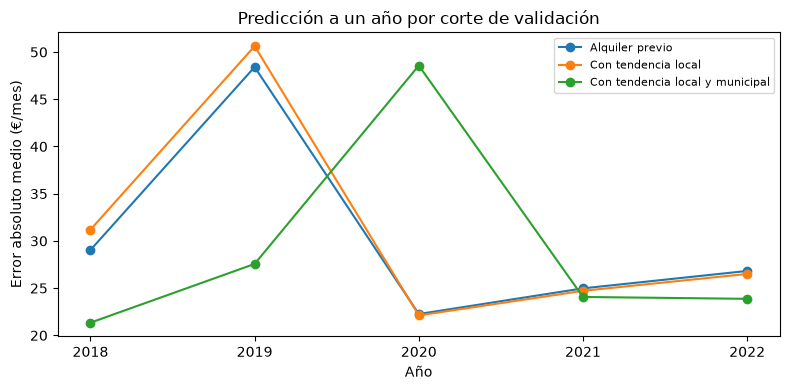

In [ ]:
train = historial[historial.anio <= 2022]
val = historial[historial.anio > 2022]
modelos = {nombre: LinearRegression().fit(train[v], train[objetivo])
           for nombre, v in variables.items()}
filas = []
for periodo, muestra in [("Entrenamiento", train), ("2023", val[val.anio == 2023]),
                          ("2024", val[val.anio == 2024]), ("2023–2024", val)]:
    # Cada método se evalúa con las mismas filas. Así la cobertura no explica la diferencia de error.
    errores = {nombre: medir(muestra[objetivo], modelos[nombre].predict(muestra[v]))
               for nombre, v in variables.items()}
    filas.append({"Periodo": periodo, "n": len(muestra),
                  "Repetir alquiler": medir(muestra[objetivo], muestra.anterior), **errores})
tabla = pd.DataFrame(filas).set_index("Periodo")
print(tabla.round(2).to_string())
brecha = 100 * (tabla.loc["2023–2024", ganador] / tabla.loc["Entrenamiento", ganador] - 1)
print(f"Modelo elegido: {ganador}. Brecha relativa de MAE: {brecha:.1f} %.")
ax = cv.pivot(index="Año", columns="Modelo", values="MAE").plot(marker="o", figsize=(8, 4))
ax.set(ylabel="Error absoluto medio (€/mes)", title="Predicción a un año por corte de validación", xticks=range(2018, 2023))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Comprobación del umbral del 5 %
Aplicamos las dos métricas al mismo modelo seleccionado y a las mismas filas. Para el MAE calculamos la variación absoluta respecto al error de entrenamiento. Para R² mostramos la diferencia absoluta en puntos porcentuales y, por separado, su magnitud relativa respecto al R² de entrenamiento. El material disponible menciona el 5 % sin identificar la fórmula oficial. Conservamos MAE como medida principal del error en euros.

In [ ]:
from sklearn.metrics import r2_score

ajuste = modelos[ganador]
resultados = {}
for nombre, muestra in [("Entrenamiento", train), ("Validación", val)]:
    predichos = ajuste.predict(muestra[variables[ganador]])
    resultados[nombre] = [mean_absolute_error(muestra[objetivo], predichos),
                          r2_score(muestra[objetivo], predichos)]
medidas = pd.DataFrame(resultados, index=["MAE €/mes", "R²"])
print(medidas.round(4).to_string())
diferencia = (medidas.Validación - medidas.Entrenamiento).abs()
# Dividimos por el valor de entrenamiento: una diferencia de puntos de R² y una variación relativa son magnitudes distintas.
relativa = 100 * diferencia / medidas.Entrenamiento.abs()
print(f"Brecha relativa de MAE: {relativa.iloc[0]:.2f} %")
print(f"Diferencia absoluta de R²: {100*diferencia.iloc[1]:.2f} puntos porcentuales")
print(f"Brecha relativa de R²: {relativa.iloc[1]:.2f} %")

           Entrenamiento  Validación
MAE €/mes        22.9766     27.1161
R²                0.9405      0.9375
Brecha relativa de MAE: 18.02 %
Diferencia absoluta de R²: 0.30 puntos porcentuales
Brecha relativa de R²: 0.32 %


## ¿Cuánto queda a fin de mes según la experiencia?
Base común de 2024. Usamos las bandas de Data Analyst en Málaga de IndesIA/TalentHackers y los ingresos netos de Eurostat para una persona sola sin hijos en España. Interpolamos entre los dos niveles de bruto más cercanos y repartimos el neto anual en doce meses.

Suponemos que una persona asume todo el alquiler municipal mediano declarado. Para los demás gastos tomamos la media por persona de la EPF de Andalucía. Excluimos el índice general y todo el grupo 04 de vivienda para evitar duplicidades. Añadimos una partida editable de 100 €/mes para suministros y otros gastos corrientes del grupo 04. El gasto de una persona que vive sola puede diferir de la media regional.

In [ ]:
import numpy as np

anio_base = 2024
suministros_y_otros_04 = 100
salarios = leer("salario_data_analyst").query("anio_informe == @anio_base")
fiscalidad = leer("fiscalidad_siete_paises")
escala = fiscalidad.query("pais == 'ES' and anio == @anio_base and moneda == 'EUR'")
escala = escala[escala.perfil.str.startswith("P1_NCH_AW")].pivot(
    index="perfil", columns="concepto", values="euros_anuales").sort_values("GRS")
def neto_mensual(bruto):
    if not escala.GRS.min() <= bruto <= escala.GRS.max():
        raise ValueError("El bruto queda fuera de la escala disponible")
    return np.interp(bruto, escala.GRS, escala.NET) / 12

epf = leer("gastos_andalucia").query("Periodo == @anio_base")
codigos = epf["Grupos de gasto (2 dígitos)"].str.extract(r"^(\d{2})")[0]
# El grupo 04 incluye vivienda. Excluirlo evita sumar el alquiler dos veces; los suministros se añaden aparte.
gasto_sin_04 = epf.loc[codigos.notna() & codigos.ne("04"), "euros_persona_anio"].sum() / 12
otros = gasto_sin_04 + suministros_y_otros_04
alquiler_base = ciudad.loc[ciudad.anio.eq(anio_base), objetivo].item()
perfiles = {"0-2": "Júnior", "2-5": "Intermedio", "5-10": "Sénior"}
filas_perfil = []
for banda in salarios.itertuples():
    minimo, maximo = banda.banda_inferior_eur_anuales, banda.banda_superior_eur_anuales
    for tramo, bruto in [("Inferior", minimo), ("Central", (minimo + maximo)/2), ("Superior", maximo)]:
        neto = neto_mensual(bruto)
        filas_perfil.append([perfiles[banda.experiencia_anios], tramo, bruto, neto,
                            alquiler_base, otros, neto - alquiler_base - otros])
presupuesto = pd.DataFrame(filas_perfil, columns=["Perfil", "Tramo", "Bruto anual", "Neto mensual",
                                                   "Alquiler", "Otros gastos", "Saldo mensual"])
print(presupuesto.round(2).to_string(index=False))
print(f"Otros gastos: {gasto_sin_04:.2f} € observados + {suministros_y_otros_04:.2f} € supuestos.")

    Perfil    Tramo  Bruto anual  Neto mensual  Alquiler  Otros gastos  Saldo mensual
    Júnior Inferior      22000.0       1523.37    718.33        793.19          11.85
    Júnior  Central      24750.0       1670.39    718.33        793.19         158.87
    Júnior Superior      27500.0       1826.52    718.33        793.19         314.99
Intermedio Inferior      27500.0       1826.52    718.33        793.19         314.99
Intermedio  Central      32250.0       2094.16    718.33        793.19         582.64
Intermedio Superior      37000.0       2355.88    718.33        793.19         844.36
    Sénior Inferior      37000.0       2355.88    718.33        793.19         844.36
    Sénior  Central      39750.0       2505.29    718.33        793.19         993.77
    Sénior Superior      42500.0       2654.71    718.33        793.19        1143.19
Otros gastos: 693.19 € observados + 100.00 € supuestos.


### Sensibilidad del ahorro hasta 2035
Tomamos el centro de cada banda salarial y mantenemos fijos el sueldo neto y los gastos distintos del alquiler en euros nominales. ¿Cuánto margen queda si solo cambia el alquiler? Las tasas anuales son supuestos editables. Un saldo negativo indica cuánto faltaría para cubrir el presupuesto.

In [ ]:
centrales = presupuesto.query("Tramo == 'Central'")
escenarios = []
for anio in [2030, 2035]:
    # Solo cambia el alquiler en este ejercicio: así se puede aislar su efecto sobre el saldo mensual.
    for tasa in [0, 0.02, 0.04]:
        alquiler = alquiler_base * (1 + tasa) ** (anio - anio_base)
        for _, perfil in centrales.iterrows():
            saldo = perfil["Neto mensual"] - otros - alquiler
            escenarios.append([anio, f"{tasa:.0%}", perfil["Perfil"], saldo])
saldos = pd.DataFrame(escenarios, columns=["Año", "Subida anual", "Perfil", "Saldo €/mes"])
print(saldos.pivot(index=["Año", "Subida anual"], columns="Perfil", values="Saldo €/mes")[
    ["Júnior", "Intermedio", "Sénior"]].round(2).to_string())

Perfil             Júnior  Intermedio  Sénior
Año  Subida anual                            
2030 0%            158.87      582.64  993.77
     2%             68.24      492.01  903.15
     4%            -31.72      392.05  803.19
2035 0%            158.87      582.64  993.77
     2%            -15.95      407.81  818.95
     4%           -228.64      195.13  606.27


## Atlas de Málaga · ¿en qué secciones alcanzaría el sueldo júnior?
Tomamos las medianas declaradas de SERPAVI en 2024 y situamos cada sección sobre el mapa del INE de 2021 por código CUSEC. Los límites son los de esa cartografía de referencia. Cada sección cuenta una vez, con independencia de cuántas viviendas tenga. Las medianas de contratos declarados y los precios de los anuncios pueden diferir.

El primer mapa muestra el alquiler mediano publicado. El segundo muestra el error absoluto de la predicción a un año del modelo seleccionado, entrenado hasta 2022. El gris señala las secciones sin el dato necesario para cada mapa. En la tabla inferior calculamos cuánto alquiler permitiría pagar cada sueldo central conservando los demás gastos del presupuesto y un ahorro mínimo editable.

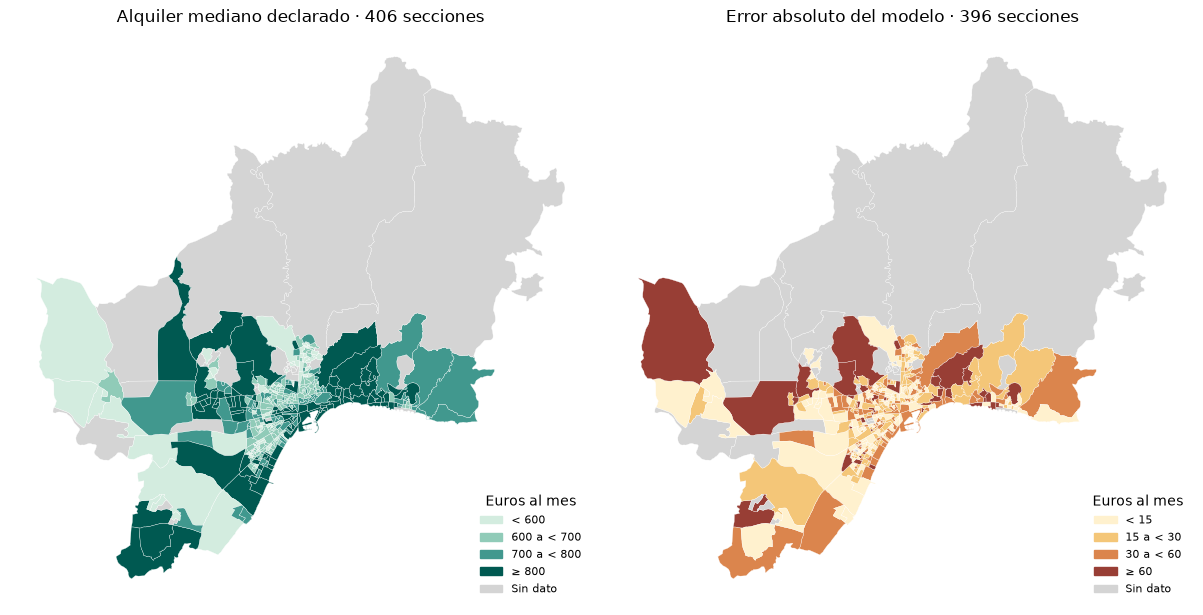

Objetivo de ahorro: 200 €/mes. Secciones con mediana publicada: 406
    Perfil  Alquiler máximo €/mes  Secciones compatibles  % de secciones
    Júnior                 677.20                    204           50.25
Intermedio                1100.97                    392           96.55
    Sénior                1512.11                    405           99.75
Error absoluto mediano: 21.09 €/mes. Error inferior a 30 €: 269 de 396 secciones.


In [ ]:
import json
from matplotlib.collections import PatchCollection
from matplotlib.patches import PathPatch, Patch
from matplotlib.path import Path as RutaMapa

with ZipFile(archivo) as atlas:
    geografia = json.loads(atlas.read("Datos_Malaga/mapa_secciones_malaga_2021.geojson"))
anio_mapa = 2024
observados = panel.loc[panel.anio.eq(anio_mapa)].set_index("zona")[objetivo].dropna()
prueba = val.loc[val.anio.eq(anio_mapa)].set_index("zona")
prediccion = modelos[ganador].predict(prueba[variables[ganador]])
# El valor absoluto expresa en euros el tamaño del error de cada sección, tanto por exceso como por defecto.
errores = (prueba[objetivo] - prediccion).abs()

piezas, codigos_mapa = [], []
for seccion in geografia["features"]:
    geometria = seccion["geometry"]
    poligonos = geometria["coordinates"] if geometria["type"] == "MultiPolygon" else [geometria["coordinates"]]
    for poligono in poligonos:
        contornos = [RutaMapa(np.asarray(anillo), closed=True) for anillo in poligono]
        piezas.append(PathPatch(RutaMapa.make_compound_path(*contornos)))
        codigos_mapa.append(seccion["properties"]["CUSEC"])
assert observados.index.isin(codigos_mapa).all() and errores.index.isin(codigos_mapa).all()

fig, ejes = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
escalas = [
    (observados, [600, 700, 800], ["#d3ecdf", "#90cbb8", "#41988e", "#005951"], "Alquiler mediano declarado"),
    (errores, [15, 30, 60], ["#fff1ce", "#f4c678", "#db854d", "#983e35"], "Error absoluto del modelo"),
]
for eje, (serie, cortes, colores, titulo) in zip(ejes, escalas):
    valores = serie.reindex(codigos_mapa).to_numpy()
    tonos = [colores[np.searchsorted(cortes, v, side="right")] if pd.notna(v) else "#d4d4d4" for v in valores]
    eje.add_collection(PatchCollection(piezas, facecolors=tonos, edgecolors="white", linewidths=0.22))
    eje.autoscale()
    eje.set_aspect(1 / np.cos(np.radians(36.7)))
    eje.set_axis_off()
    eje.set_title(f"{titulo} · {len(serie)} secciones")
    etiquetas = [f"< {cortes[0]}", f"{cortes[0]} a < {cortes[1]}", f"{cortes[1]} a < {cortes[2]}", f"≥ {cortes[2]}", "Sin dato"]
    eje.legend(handles=[Patch(color=c, label=l) for c, l in zip(colores + ["#d4d4d4"], etiquetas)],
               title="Euros al mes", loc="lower right", fontsize=8, frameon=False)
plt.show()

ahorro_minimo = 200
filas_atlas = []
for _, perfil in centrales.iterrows():
    maximo = perfil["Neto mensual"] - otros - ahorro_minimo
    compatibles = int(observados.le(maximo).sum())
    filas_atlas.append([perfil["Perfil"], maximo, compatibles, 100 * compatibles / len(observados)])
print(f"Objetivo de ahorro: {ahorro_minimo} €/mes. Secciones con mediana publicada: {len(observados)}")
print(pd.DataFrame(filas_atlas, columns=["Perfil", "Alquiler máximo €/mes", "Secciones compatibles", "% de secciones"]).round(2).to_string(index=False))
print(f"Error absoluto mediano: {errores.median():.2f} €/mes. Error inferior a 30 €: {(errores < 30).sum()} de {len(errores)} secciones.")

La tabla cuenta las secciones cuya mediana permite el ahorro elegido. Dentro de una misma sección puede haber alquileres por encima y por debajo de la mediana. El porcentaje describe la distribución territorial y no estima la probabilidad de encontrar vivienda disponible.

## Comprar en Málaga · ¿cuántos meses de ahorro exige la entrada?
Usamos el valor tasado medio municipal de vivienda libre del cuarto trimestre de 2024 para mantener la comparación con los salarios y el presupuesto del mismo año. Multiplicamos el valor por metro cuadrado por una superficie editable. La tasación municipal aproxima el precio de un piso hipotético. El precio pactado de una vivienda concreta puede diferir.

La entrada es la parte del precio que aporta la persona. Sumamos una provisión editable para gastos de compra y restamos los ahorros iniciales. El ejemplo supone que se guarda cada mes todo el saldo disponible tras pagar el alquiler y los demás gastos. Mantenemos constantes ese saldo y el objetivo, sin intereses sobre el ahorro. El resultado mide el tiempo para reunir el dinero inicial. La concesión y la cuota de la hipoteca exigirían otro cálculo.

In [ ]:
from math import ceil

superficie_m2 = 70
fraccion_financiada = 0.80
fraccion_gastos = 0.10  # Provisión de escenario, editable
ahorro_inicial = 0
if superficie_m2 <= 0 or not 0 <= fraccion_financiada <= 1 or min(fraccion_gastos, ahorro_inicial) < 0:
    raise ValueError("Revisa la superficie, la financiación, los gastos y el ahorro inicial.")

compra = leer("compra_malaga")
eur_m2 = compra.loc[compra.anio.eq(anio_base) & compra.trimestre.eq(4), "valor_tasado_eur_m2"].item()
precio = superficie_m2 * eur_m2
entrada = precio * (1 - fraccion_financiada)
gastos_compra = precio * fraccion_gastos
objetivo_inicial = round(entrada + gastos_compra, 2)
pendiente = max(0, objetivo_inicial - ahorro_inicial)
print(f"{anio_base} T4 · {eur_m2:.2f} €/m² · Vivienda: {precio:,.2f} €")
print(f"Entrada: {entrada:,.2f} € · Gastos: {gastos_compra:,.2f} € · Pendiente: {pendiente:,.2f} €")

def meses_para_entrada(saldo):
    if pendiente == 0:
        return 0
    if saldo <= 0:
        return None
    # Una fracción de mes exige una aportación mensual adicional para completar la entrada.
    return ceil(pendiente / saldo)

def expresar_plazo(meses):
    if meses is None:
        return "Inalcanzable con este saldo"
    anios, resto = divmod(meses, 12)
    return f"{anios} años y {resto} " + ("mes" if resto == 1 else "meses")

plazos = presupuesto[["Perfil", "Tramo", "Saldo mensual"]].copy()
plazos["Tiempo para reunir entrada y gastos"] = [
    expresar_plazo(meses_para_entrada(saldo)) for saldo in plazos["Saldo mensual"]]
print(plazos.round(2).to_string(index=False))

2024 T4 · 2730.80 €/m² · Vivienda: 191,156.00 €
Entrada: 38,231.20 € · Gastos: 19,115.60 € · Pendiente: 57,346.80 €
    Perfil    Tramo  Saldo mensual Tiempo para reunir entrada y gastos
    Júnior Inferior          11.85                  403 años y 4 meses
    Júnior  Central         158.87                     30 años y 1 mes
    Júnior Superior         314.99                   15 años y 3 meses
Intermedio Inferior         314.99                   15 años y 3 meses
Intermedio  Central         582.64                    8 años y 3 meses
Intermedio Superior         844.36                    5 años y 8 meses
    Sénior Inferior         844.36                    5 años y 8 meses
    Sénior  Central         993.77                   4 años y 10 meses
    Sénior Superior        1143.19                    4 años y 3 meses


## Después de reunir la entrada · ¿qué cuota podría sostener cada perfil?
Comparamos el presupuesto mensual del alquiler con el de la vivienda comprada. Usamos el tipo medio de las nuevas operaciones en España del BCE correspondiente a diciembre del año base. Para esta simulación lo tratamos como un tipo nominal anual constante durante 30 años con cuotas mensuales iguales. Es un escenario retrospectivo con datos de 2024.

Conservamos los gastos personales y los suministros del presupuesto anterior. Añadimos una provisión mensual editable de 100 € para comunidad, IBI, seguros adicionales y mantenimiento. Sustitúyela por los costes de un inmueble concreto. El saldo muestra la liquidez mensual después de pagar. La cuota incluye amortización de capital e intereses. El porcentaje de sueldo dedicado a la cuota describe el esfuerzo de cada perfil y no determina la aprobación bancaria.

In [ ]:
plazo_anios = 30
costes_propietario = 100
tipos = leer("hipotecas_nuevas_espana")
periodo = f"{anio_base}-12"
tipo_base = tipos.loc[tipos.TIME_PERIOD.eq(periodo), "OBS_VALUE"].item()
capital = precio * fraccion_financiada

def cuota_mensual(capital, tipo_porcentaje, anios):
    if capital < 0 or tipo_porcentaje < 0 or anios <= 0:
        raise ValueError("Revisa el capital, el tipo y el plazo.")
    meses = anios * 12
    # La fórmula de cuota utiliza un tipo por mes: dividimos el porcentaje anual entre 100 y después entre 12.
    tasa = tipo_porcentaje / 1200
    if tasa == 0:
        return capital / meses
    return capital * tasa / (1 - (1 + tasa) ** -meses)

cuota = cuota_mensual(capital, tipo_base, plazo_anios)
print(f"Capital {capital:.2f} € | Tipo de referencia {tipo_base:.2f} % | Cuota {cuota:.2f} €/mes")
comparativa = centrales[["Perfil", "Neto mensual", "Saldo mensual"]].copy()
comparativa = comparativa.rename(columns={"Saldo mensual": "Saldo alquilando"})
comparativa["Cuota / neto (%)"] = 100 * cuota / comparativa["Neto mensual"]
comparativa["Saldo comprando"] = comparativa["Neto mensual"] - otros - costes_propietario - cuota
print(comparativa.round(2).to_string(index=False))
print("Sensibilidad del pago mensual si cambia el tipo al contratar:")
for tipo in [max(0, tipo_base-1), tipo_base, tipo_base+1]:
    print(f"{tipo:.2f} % → {cuota_mensual(capital, tipo, plazo_anios):.2f} €/mes")

Capital 152924.80 € | Tipo de referencia 2.90 % | Cuota 636.52 €/mes
    Perfil  Neto mensual  Saldo alquilando  Cuota / neto (%)  Saldo comprando
    Júnior       1670.39            158.87             38.11           140.69
Intermedio       2094.16            582.64             30.39           564.45
    Sénior       2505.29            993.77             25.41           975.59
Sensibilidad del pago mensual si cambia el tipo al contratar:
1.90 % → 557.62 €/mes
2.90 % → 636.52 €/mes
3.90 % → 721.30 €/mes


## Conclusión · ¿para quién es factible quedarse?
Con las condiciones del escenario de 2024, un analista júnior con sueldo en el centro de su banda puede cubrir el alquiler mediano municipal y los demás gastos presupuestados. Le quedan **159 €/mes**, por debajo del objetivo elegido de 200 €. La ubicación cambia la respuesta: en **204 de 406 secciones** la mediana publicada sí permite alcanzar ese objetivo. Con el sueldo central intermedio, el margen municipal sube a **583 €/mes**.

El modelo ayuda a anticipar el alquiler a un año: en las mismas 786 observaciones de 2023 y 2024 reduce el error absoluto medio de **47,67 € a 27,12 €/mes** frente a repetir el alquiler anterior. El R² es 0,9405 en entrenamiento y 0,9375 en validación. La brecha relativa del R² es del 0,32 % y la del MAE, del 18,02 %. La aplicación del umbral del 5 % depende de la métrica que especifique la evaluación.

Para 2035, el proyecto permite cambiar supuestos y medir consecuencias. Por ejemplo, con un alquiler que crece un 2 % anual y los demás importes fijos, el margen júnior pasa a **−16 €/mes**. Un crecimiento del PIB nacional puede coexistir con dificultades para quedarse en Málaga. El ahorro y el coste de vivienda cuantifican una parte de la decisión. La satisfacción personal dependerá también de circunstancias que estos datos agregados no recogen.

**Fuentes y trazabilidad.** El archivo Datos_Malaga/LEEME.md del ZIP documenta la procedencia, unidades y fechas de las series utilizadas, con enlaces a sus originales.

## Nivel 2 · Gradient Boosting y seguimiento del modelo
El ensemble aprende el cambio respecto al alquiler anterior. Los árboles corrigen sucesivamente errores de los anteriores. Aplicamos GridSearchCV a cuatro combinaciones de profundidad y tamaño mínimo de hoja. En cinco cortes, de 2018 a 2022, cada validación contiene un año completo y el entrenamiento solo años anteriores. 2023 y 2024 quedan fuera de la búsqueda. Ya se habían analizado en el proyecto y constituyen una evaluación retrospectiva.

La app y esta sección comparten el entrenamiento en modelo.py. Las predicciones del bloque anterior corresponden a regresión lineal. El modelo de conjunto tiene su propia evaluación.

Configuración elegida: {'max_depth': 2, 'min_samples_leaf': 15}
                  n      MAE     RMSE      R²
Periodo                                      
Entrenamiento  3549  21.3748  29.8423  0.9470
Validación      786  30.5196  43.8975  0.9244
MAE en cada corte para la configuración elegida:
2018 25.22
2019 35.09
2020 31.02
2021 24.2
2022 24.62
Brecha relativa de R² (%): 2.39
Brecha relativa de MAE (%): 42.78


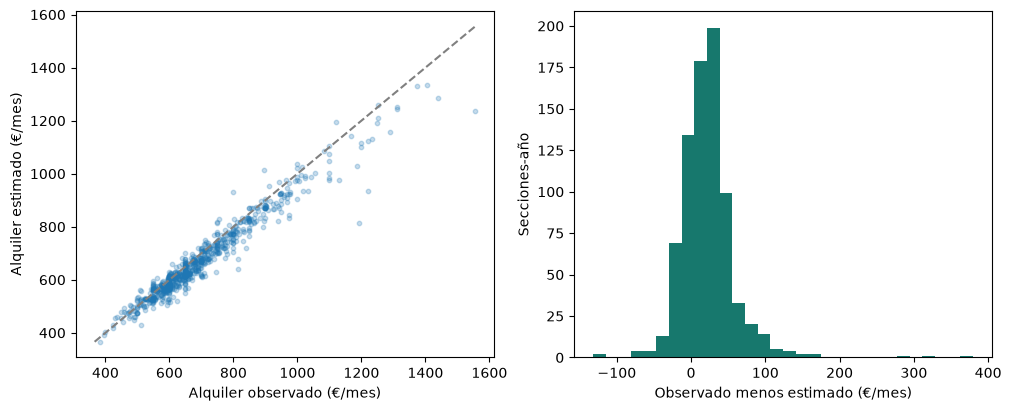

Importancia para predecir el cambio:
cambio_ciudad     0.811
cambio_seccion    0.154
anterior          0.036
dtype: float64


In [ ]:
from modelo import entrenar, VARIABLES
# La aplicación llama a la misma función. El ajuste y las variables se pueden revisar en modelo.py.
tabla_ensemble, busqueda, rendimiento = entrenar(archivo)
print("Configuración elegida:", busqueda.best_params_)
print(rendimiento.round(4).to_string())
cv_ensemble = pd.DataFrame(busqueda.cv_results_)
print("MAE en cada corte para la configuración elegida:")
for i, anio in enumerate(range(2018, 2023)):
    print(anio, round(-cv_ensemble.loc[busqueda.best_index_, f"split{i}_test_score"], 2))
brechas = (rendimiento.loc["Validación"] / rendimiento.loc["Entrenamiento"] - 1).abs() * 100
print("Brecha relativa de R² (%):", round(brechas["R²"], 2))
print("Brecha relativa de MAE (%):", round(brechas["MAE"], 2))
pruebas = tabla_ensemble.loc[2023:2024].dropna(subset=["real"])
# Un residuo positivo indica que el alquiler observado superó la estimación. La gráfica muestra también los errores extremos.
residuos = pruebas.real - pruebas.estimado
fig, ax = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
ax[0].scatter(pruebas.real, pruebas.estimado, alpha=.25, s=10)
limites = [pruebas[["real","estimado"]].min().min(), pruebas[["real","estimado"]].max().max()]
ax[0].plot(limites, limites, "--", color="grey")
ax[0].set(xlabel="Alquiler observado (€/mes)", ylabel="Alquiler estimado (€/mes)")
ax[1].hist(residuos, bins=30, color="#17786d")
ax[1].set(xlabel="Observado menos estimado (€/mes)", ylabel="Secciones-año")
plt.show()
print("Importancia para predecir el cambio:")
print(pd.Series(busqueda.best_estimator_.feature_importances_, index=VARIABLES).sort_values(ascending=False).round(3))


**Interpretación.** En las mismas 786 observaciones, el modelo lineal obtiene un MAE de 27,12 €/mes y Gradient Boosting, 30,52 €/mes. Ambos mejoran la referencia de repetir el último alquiler (47,67 €/mes). La mayor complejidad no mejoró el error final en euros. Para el ensemble la brecha relativa de R² queda en 2,39 % y la de MAE en 42,78 %. La rúbrica pide menos del 5 % sin precisar fórmula. Presentamos ambas y mantenemos el MAE como indicador principal de precisión.

**Seguimiento e ingestión.** Ejecuta app_malaga.py. En las secciones con predicción y sin mediana publicada en el ZIP, el formulario recoge una nueva mediana de sección y su fuente. El indicador MAE se actualiza al guardarla. Las observaciones quedan en una base local y se exportan a CSV con año, sección, objetivo observado y las tres variables del modelo. La revisión de la fuente precede a cualquier reentrenamiento.


## Evaluación final del modelo y sobreajuste

### Modelo elegido: Gradient Boosting Regressor

El modelo estima el alquiler mediano mensual de las
secciones censales de Málaga utilizando datos históricos.

### Resultados

| Métrica | Entrenamiento | Validación |
|---|---:|---:|
| MAE | 21,38 € | 30,52 € |
| RMSE | 29,84 € | 43,90 € |
| R² | 0,947 | 0,924 |

### Comparación con el modelo sencillo

- Modelo sencillo: MAE = 47,67 €.
- Gradient Boosting: MAE = 30,52 €.
- Reducción del error: aproximadamente 36 %.

### Evaluación del sobreajuste

- Diferencia relativa de R²: 2,43 %.
- Diferencia relativa de MAE: 42,78 %.

La diferencia relativa de R² es inferior al 5 %,
mientras que la del MAE supera ese umbral.

Estos resultados no permiten afirmar que el requisito
de sobreajuste esté cumplido sin precisar previamente
la métrica y el criterio establecido en el enunciado.

La validación temporal de 2023–2024 muestra que el
modelo generaliza razonablemente, aunque el aumento
del error respecto al entrenamiento requiere análisis.

### Conclusión

Gradient Boosting mejora las predicciones respecto
al método sencillo y permite estudiar diferencias
territoriales en el alquiler de Málaga.

Las proyecciones hasta 2035 basadas en tasas anuales
constantes son escenarios exploratorios y no deben
confundirse con predicciones validadas del modelo.


In [ ]:

from modelo import preparar, VARIABLES
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

datos = preparar("Atlas_Malaga_datos.zip")
datos = datos.dropna(subset=["real"])

train = datos[datos.anio <= 2022]
val = datos[datos.anio.between(2023, 2024)]

configuraciones = [
    ("Muy sencillo", 15, 1, 45),
    ("Sencillo", 30, 1, 45),
    ("Moderado", 40, 2, 45),
    ("Más regularizado", 40, 1, 100),
]

resultados = []

for nombre, arboles, profundidad, hoja in configuraciones:
    modelo = GradientBoostingRegressor(
        n_estimators=arboles,
        max_depth=profundidad,
        min_samples_leaf=hoja,
        loss="huber",
        random_state=42
    )

    modelo.fit(
        train[VARIABLES],
        train.real - train.anterior
    )

    pred_train = train.anterior + modelo.predict(train[VARIABLES])
    pred_val = val.anterior + modelo.predict(val[VARIABLES])

    mae_train = mean_absolute_error(train.real, pred_train)
    mae_val = mean_absolute_error(val.real, pred_val)
    r2_train = r2_score(train.real, pred_train)
    r2_val = r2_score(val.real, pred_val)

    resultados.append({
        "Modelo": nombre,
        "MAE entrenamiento": round(mae_train, 2),
        "MAE validación": round(mae_val, 2),
        "Brecha MAE %": round(
            100 * abs(mae_val - mae_train) / mae_train, 2
        ),
        "R² validación": round(r2_val, 3),
        "Brecha R² %": round(
            100 * abs(r2_val - r2_train) / abs(r2_train), 2
        )
    })

display(pd.DataFrame(resultados))


,Modelo,MAE entrenamiento,MAE validación,Brecha MAE %,R² validación,Brecha R² %
0,Muy sencillo,23.58,30.55,29.58,0.924,1.25
1,Sencillo,23.07,29.69,28.74,0.927,1.25
2,Moderado,21.42,30.50,42.40,0.924,2.35
3,Más regularizado,22.83,29.66,29.90,0.927,1.37


In [ ]:

# SPAIN 2035 — Comparación mediante validación temporal

from modelo import preparar, VARIABLES
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

datos = preparar("Atlas_Malaga_datos.zip")
datos = datos[(datos.anio <= 2022) & datos.real.notna()]

modelos = [
    ("Muy sencillo", 15, 1, 45),
    ("Sencillo", 30, 1, 45),
    ("Moderado", 40, 2, 45),
    ("Más regularizado", 40, 1, 100)
]

resultados = []

for nombre, arboles, profundidad, hoja in modelos:
    errores = []

    for anio in range(2018, 2023):
        entrenamiento = datos[datos.anio < anio]
        validacion = datos[datos.anio == anio]

        if entrenamiento.empty or validacion.empty:
            continue

        modelo = GradientBoostingRegressor(
            n_estimators=arboles,
            max_depth=profundidad,
            min_samples_leaf=hoja,
            loss="huber",
            random_state=42
        )

        modelo.fit(
            entrenamiento[VARIABLES],
            entrenamiento.real - entrenamiento.anterior
        )

        prediccion = (
            validacion.anterior
            + modelo.predict(validacion[VARIABLES])
        )

        errores.append(
            mean_absolute_error(validacion.real, prediccion)
        )

    resultados.append({
        "Modelo": nombre,
        "MAE temporal medio": round(sum(errores)/len(errores), 2),
        "Cortes evaluados": len(errores)
    })

tabla = pd.DataFrame(resultados)
display(tabla.sort_values("MAE temporal medio"))


,Modelo,MAE temporal medio,Cortes evaluados
2,Moderado,28.16,5
3,Más regularizado,28.57,5
0,Muy sencillo,28.63,5
1,Sencillo,28.85,5


In [ ]:

from modelo import entrenar

predicciones, busqueda, metricas = entrenar(
    "Atlas_Malaga_datos.zip"
)

print("CONFIGURACIÓN ELEGIDA POR GRIDSEARCHCV")
print(busqueda.best_params_)

print("\nMAE MEDIO DE VALIDACIÓN TEMPORAL")
print(round(-busqueda.best_score_, 2), "€/mes")

print("\nMÉTRICAS DEL MODELO")
display(metricas.round(3))


CONFIGURACIÓN ELEGIDA POR GRIDSEARCHCV
{'max_depth': 2, 'min_samples_leaf': 15}

MAE MEDIO DE VALIDACIÓN TEMPORAL
28.03 €/mes

MÉTRICAS DEL MODELO


,n,MAE,RMSE,R²
Periodo,,,,
Entrenamiento,3549,21.375,29.842,0.947
Validación,786,30.520,43.898,0.924


In [24]:

# ============================================================
# SPAIN 2035 — EVALUACIÓN Y CONTROL DEL SOBREAJUSTE
# ============================================================

# Importamos la función que entrena nuestro modelo de alquiler.
# Esta función también devuelve las métricas de rendimiento.
from modelo import entrenar

# Entrenamos con datos históricos hasta 2022.
# Los años 2023 y 2024 se reservan para validar el modelo.
predicciones, modelo, metricas = entrenar(
    "Atlas_Malaga_datos.zip"
)

# Recuperamos las métricas de cada conjunto.
train = metricas.loc["Entrenamiento"]
val = metricas.loc["Validación"]

# Calculamos la diferencia relativa del error MAE.
# El MAE expresa cuántos euros nos equivocamos, en promedio.
brecha_mae = (
    abs(val["MAE"] - train["MAE"])
    / train["MAE"] * 100
)

# Calculamos la diferencia relativa del R².
# R² mide la proporción de variabilidad explicada.
brecha_r2 = (
    abs(val["R²"] - train["R²"])
    / abs(train["R²"]) * 100
)

# Mostramos las métricas originales.
print("RESULTADOS DEL MODELO")
print(metricas.round(3).to_string())

# Mostramos ambas medidas de sobreajuste.
print("\nCONTROL DEL SOBREAJUSTE")
print(f"Diferencia relativa MAE: {brecha_mae:.2f} %")
print(f"Diferencia relativa R²: {brecha_r2:.2f} %")

# Evaluamos ambas métricas respecto al umbral del 5 %.
# El enunciado no precisa qué métrica debe utilizarse.
print("\nCOMPROBACIÓN DEL UMBRAL DEL 5 %")
print("MAE:", "Inferior al 5 %" if brecha_mae < 5
      else "Igual o superior al 5 %")
print("R²:", "Inferior al 5 %" if brecha_r2 < 5
      else "Igual o superior al 5 %")

# IMPORTANTE:
# Una diferencia reducida del R² no garantiza que el
# modelo esté libre de sobreajuste.
# También debemos interpretar el MAE de validación.


RESULTADOS DEL MODELO
                  n     MAE    RMSE     R²
Periodo                                   
Entrenamiento  3549  21.375  29.842  0.947
Validación      786  30.520  43.898  0.924

CONTROL DEL SOBREAJUSTE
Diferencia relativa MAE: 42.78 %
Diferencia relativa R²: 2.39 %

COMPROBACIÓN DEL UMBRAL DEL 5 %
MAE: Igual o superior al 5 %
R²: Inferior al 5 %



## Conclusiones de la evaluación del modelo

### ¿Qué hemos conseguido?

Hemos desarrollado un modelo de regresión supervisada
mediante Gradient Boosting para estimar el alquiler
mediano mensual en las secciones censales de Málaga.

El modelo fue entrenado con datos hasta 2022 y
evaluado con observaciones de 2023 y 2024.

### Capacidad predictiva

El modelo obtuvo un MAE de validación de 30,52 €
y un R² de 0,924.

Frente al método sencillo de repetir el alquiler
del año anterior, redujo el error aproximadamente
un 36 %.

### Control del sobreajuste

La diferencia relativa entre entrenamiento y
validación fue:

- R²: 2,39 %.
- MAE: 42,78 %.

La diferencia de R² se encuentra por debajo del
umbral académico del 5 %, pero la diferencia del
MAE lo supera.

Por tanto, no afirmamos que el modelo esté libre
de sobreajuste. La interpretación depende de la
métrica establecida para evaluar ese requisito.

### Limitaciones

Las estimaciones del modelo corresponden al alquiler
mediano general de cada sección, no exclusivamente
a pisos de dos habitaciones.

Las cifras futuras hasta 2035 que utilizan tasas
anuales constantes son escenarios exploratorios,
no predicciones de mercado validadas.

Los datos de validación también se han consultado
durante la comparación exploratoria de modelos.
Por ello, una evaluación definitiva requeriría
datos posteriores independientes.

### Conclusión del proyecto

SPAIN 2035 permite estudiar cómo evolucionan los
alquileres en Málaga y cómo podrían afectar a la
capacidad económica de quienes desean establecerse
en la ciudad.

El crecimiento económico puede mejorar las
oportunidades, pero no garantiza por sí solo
viviendas asequibles ni un mayor bienestar.

El proyecto proporciona herramientas para analizar
estas cuestiones con datos, modelos predictivos
y escenarios claramente diferenciados.



## Seguimiento y actualización del modelo

### Sistema de seguimiento

SPAIN 2035 dispone de una base de datos SQLite
para registrar nuevas observaciones del alquiler
publicado en las secciones censales de Málaga.

La aplicación incorpora:

- Un mecanismo para registrar observaciones.
- Una API para consultar el seguimiento del modelo.
- El cálculo del MAE cuando existen observaciones
  nuevas comparables con las predicciones.
- La exportación de registros a CSV para facilitar
  futuros reentrenamientos.

### Situación actual

La base de datos contiene cero observaciones nuevas.

Por tanto, todavía no es posible calcular un MAE
de seguimiento con datos posteriores.

### Procedimiento previsto de reentrenamiento

1. Recopilar nuevas medianas oficiales de alquiler.
2. Comprobar su procedencia, año y sección censal.
3. Incorporarlas al conjunto histórico de datos.
4. Volver a entrenar y validar temporalmente el modelo.
5. Comparar el nuevo rendimiento con el modelo anterior.
6. Actualizar el modelo únicamente si la evaluación
   justifica el cambio.

### Limitación

El registro y la exportación están implementados,
pero el reentrenamiento con nuevas observaciones
todavía no está automatizado.

No se utilizarán observaciones ficticias para
simular una mejora del rendimiento.



## Estado final del Proyecto 7 — Nivel 2

### 1. Modelo predictivo
Se implementó Gradient Boosting Regressor para
estimar el alquiler mediano de zonas de Málaga.

El modelo utiliza tres variables:
- Alquiler del año anterior.
- Variación histórica de la sección.
- Variación histórica del municipio.

### 2. Entrenamiento y validación
- Entrenamiento: hasta 2022.
- Validación: 2023 y 2024.
- Optimización: GridSearchCV.
- Validación cruzada: cinco cortes temporales.
- MAE de validación: 30,52 €/mes.
- RMSE: 43,90 €/mes.
- R²: 0,924.

Frente al método sencillo, Gradient Boosting
reduce el error aproximadamente un 36 %.

### 3. Sobreajuste
- Diferencia relativa de R²: 2,39 %.
- Diferencia relativa de MAE: 42,78 %.

La diferencia de R² es inferior al 5 %, pero la
del MAE supera ese umbral. El cumplimiento del
requisito depende de la métrica especificada.

### 4. Seguimiento del modelo
- Base de datos SQLite: comprobada.
- API de seguimiento: comprobada.
- Exportación CSV: comprobada.
- Nuevas observaciones: 0.
- Registro de nuevas observaciones: implementado,
  pendiente de prueba funcional.
- Reentrenamiento automático: no implementado.

### 5. Aplicación interactiva
La aplicación Mediterráneo de Cristal permite
consultar alquileres por zona y año, junto con
referencias de compra y alquiler de viviendas
tipo de dos habitaciones.

Las cifras futuras de vivienda son escenarios,
no predicciones de mercado validadas.

### Conclusión
SPAIN 2035 demuestra la aplicación de técnicas
de regresión, análisis exploratorio, optimización
y evaluación temporal sobre datos reales.

El proyecto permite estudiar la asequibilidad
de la vivienda en Málaga y sus posibles cambios,
distinguiendo los resultados predictivos
validados de las proyecciones exploratorias.



## Verificación funcional del sistema de seguimiento

Se realizaron cuatro pruebas automatizadas en un
entorno temporal y aislado:

1. Consulta de la API de seguimiento: correcta.
2. Consulta de la API de predicción: correcta.
3. Registro de una observación: correcto.
4. Seguimiento y exportación CSV: correctos.

Resultado: 4 de 4 pruebas satisfactorias.

La base de datos original no fue modificada.
El sistema permite registrar, consultar y exportar
nuevas observaciones para futuras actualizaciones.

Limitación: el reentrenamiento automático con
nuevas observaciones todavía no está implementado.
